# Entrenamiento del detector de matrículas (YOLO)

In [1]:
import json
import random
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image as MostrarImagen, display
from ultralytics import YOLO

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no disponible')

GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## Preparación del dataset

In [2]:
DATASET = Path('dataset')
SALIDA = Path('yolo_dataset')
VAL, TEST, SEMILLA = 0.15, 0.15, 42

In [3]:
def leer_cajas(ruta_json):
    try:
        anotaciones = json.loads(ruta_json.read_text(encoding='utf-8'))
        if isinstance(anotaciones, dict):
            anotaciones = [anotaciones]
        cajas = []
        for a in anotaciones:
            r = a.get('rectangle')
            if not (r and len(r) == 4 and all(0 <= v <= 1 for v in r) and r[2] > 0 and r[3] > 0):
                return None
            cajas.append(r)
        return cajas
    except Exception:
        return None


imagenes = sorted(p for p in (DATASET / 'images').iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
n_json = len(list((DATASET / 'annotations').glob('*.json')))

datos, sin_json, invalidos = [], [], []
for img in imagenes:
    ruta = DATASET / 'annotations' / (img.stem + '.json')
    if not ruta.exists():
        sin_json.append(img.name)
        continue
    cajas = leer_cajas(ruta)
    if cajas is None:
        invalidos.append(ruta.name)
        continue
    datos.append((img, cajas))

print(f'Imágenes: {len(imagenes)} | JSON: {n_json}')
print(f'Usadas: {len(datos)} | imágenes sin JSON: {len(sin_json)} | JSON inválidos: {len(invalidos)}')
print('Ejemplos sin JSON:', sin_json[:3])
print('Ejemplos inválidos:', invalidos[:3])
assert datos, 'Ninguna imagen tiene JSON: revisa dataset/images y dataset/annotations'

Imágenes: 2387 | JSON: 2418
Usadas: 2386 | imágenes sin JSON: 0 | JSON inválidos: 1
Ejemplos sin JSON: []
Ejemplos inválidos: ['matricula15.json']


In [4]:
random.Random(SEMILLA).shuffle(datos)
n_val, n_test = int(len(datos) * VAL), int(len(datos) * TEST)
reparto = {'val': datos[:n_val], 'test': datos[n_val:n_val + n_test], 'train': datos[n_val + n_test:]}

if SALIDA.exists():
    shutil.rmtree(SALIDA)

for nombre, lote in reparto.items():
    (SALIDA / nombre / 'images').mkdir(parents=True)
    (SALIDA / nombre / 'labels').mkdir(parents=True)
    for img, cajas in lote:
        shutil.copy2(img, SALIDA / nombre / 'images' / img.name)
        with open(SALIDA / nombre / 'labels' / f'{img.stem}.txt', 'w') as f:
            for xc, yc, w, h in cajas:
                f.write(f'0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n')
    print(f'{nombre:5s}: {len(lote):4d} imágenes, {sum(len(c) for _, c in lote):4d} matrículas')

YAML = SALIDA / 'data.yaml'
YAML.write_text(f"path: {SALIDA.resolve().as_posix()}\ntrain: train/images\nval: val/images\ntest: test/images\nnc: 1\nnames: ['plate']\n")

val  :  357 imágenes,  807 matrículas
test :  357 imágenes,  782 matrículas
train: 1672 imágenes, 3646 matrículas


220

## Comprobación de las etiquetas

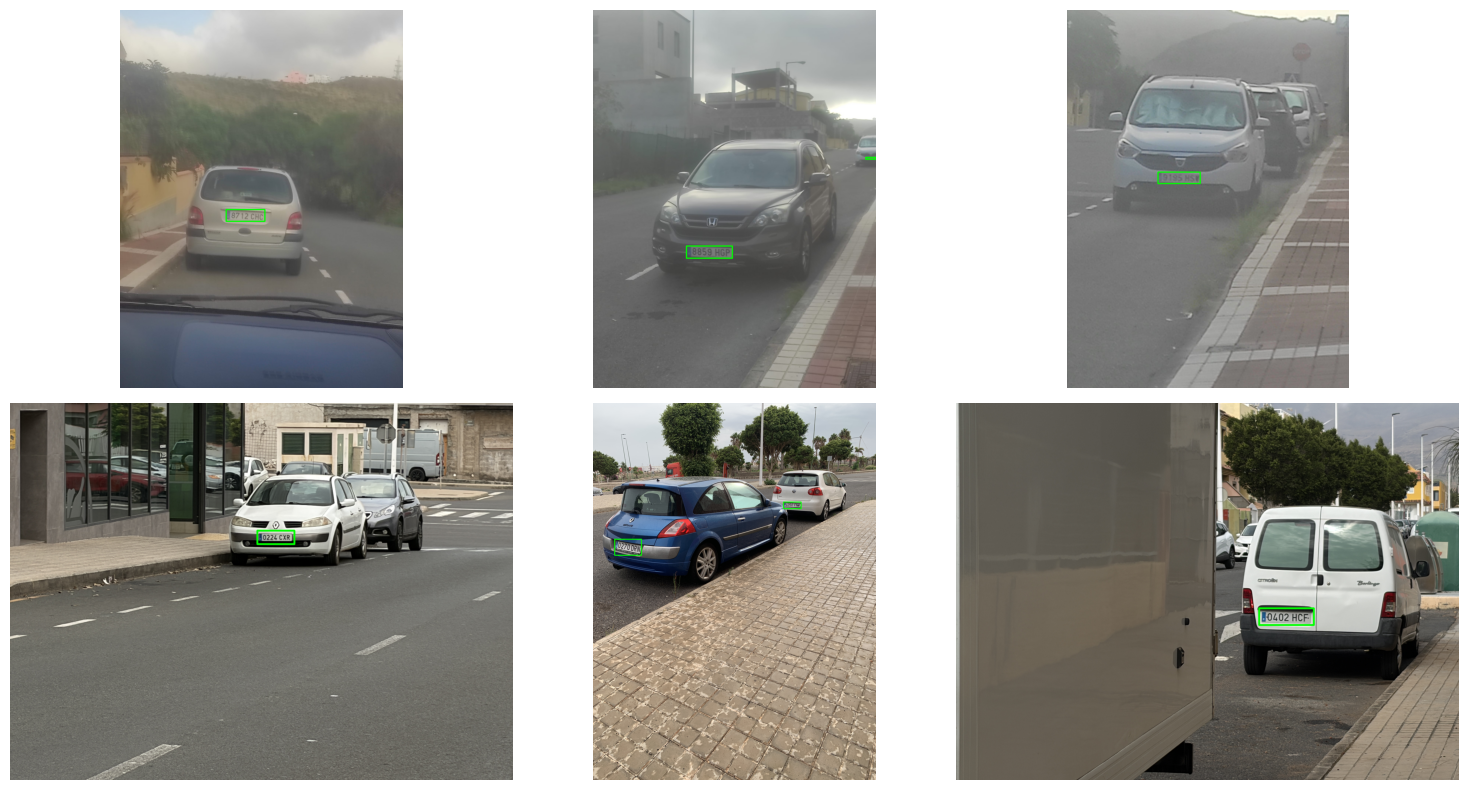

In [5]:
muestra = sorted((SALIDA / 'train' / 'images').iterdir())[:6]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, ruta in zip(ejes.ravel(), muestra):
    im = cv2.cvtColor(cv2.imread(str(ruta)), cv2.COLOR_BGR2RGB)
    H, W = im.shape[:2]
    for linea in (SALIDA / 'train' / 'labels' / f'{ruta.stem}.txt').read_text().splitlines():
        _, xc, yc, w, h = map(float, linea.split())
        cv2.rectangle(im, (int((xc - w / 2) * W), int((yc - h / 2) * H)),
                          (int((xc + w / 2) * W), int((yc + h / 2) * H)), (0, 255, 0), max(2, W // 300))
    eje.imshow(im)
    eje.axis('off')
plt.tight_layout()
plt.show()

## Entrenamiento

In [6]:
RUNS = {}


def entrenar(pesos, batch=16):
    modelo = YOLO(pesos)
    modelo.train(
        data=str(YAML), epochs=100, imgsz=640, batch=batch,
        patience=20, fliplr=0.0,
        device=0, workers=4, seed=0,
        project='runs_plates', name=Path(pesos).stem + '_plates', exist_ok=True,
    )
    RUNS[Path(pesos).stem] = Path(modelo.trainer.save_dir)

In [7]:
entrenar('yolo11n.pt')

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.11.18 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yol

In [ ]:
entrenar('yolo11s.pt')

## Análisis del entrenamiento

===== yolo11n =====


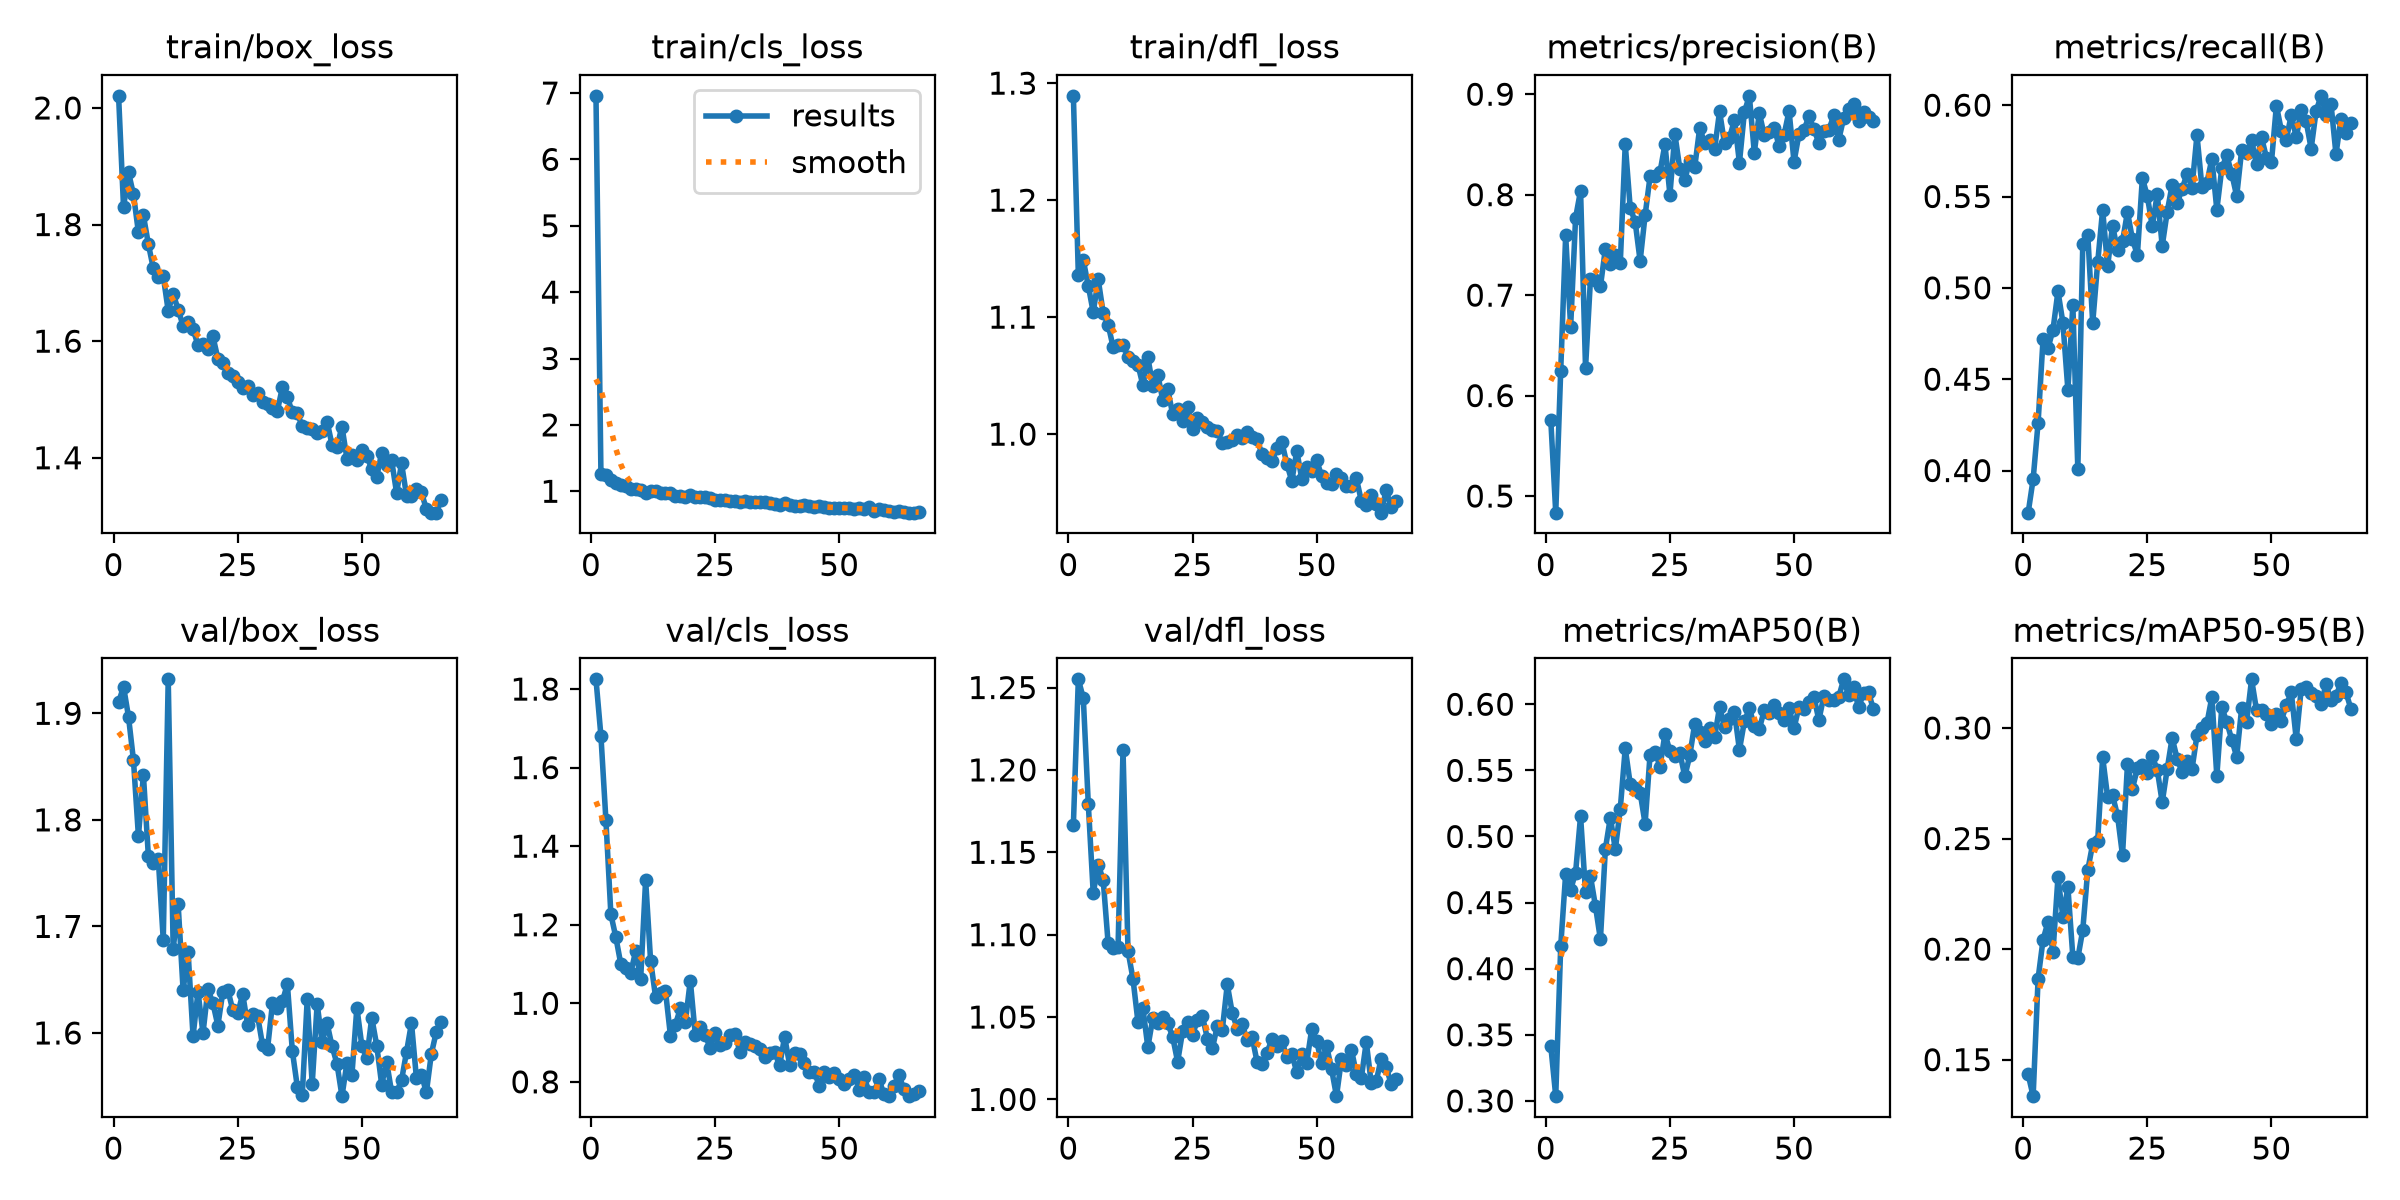

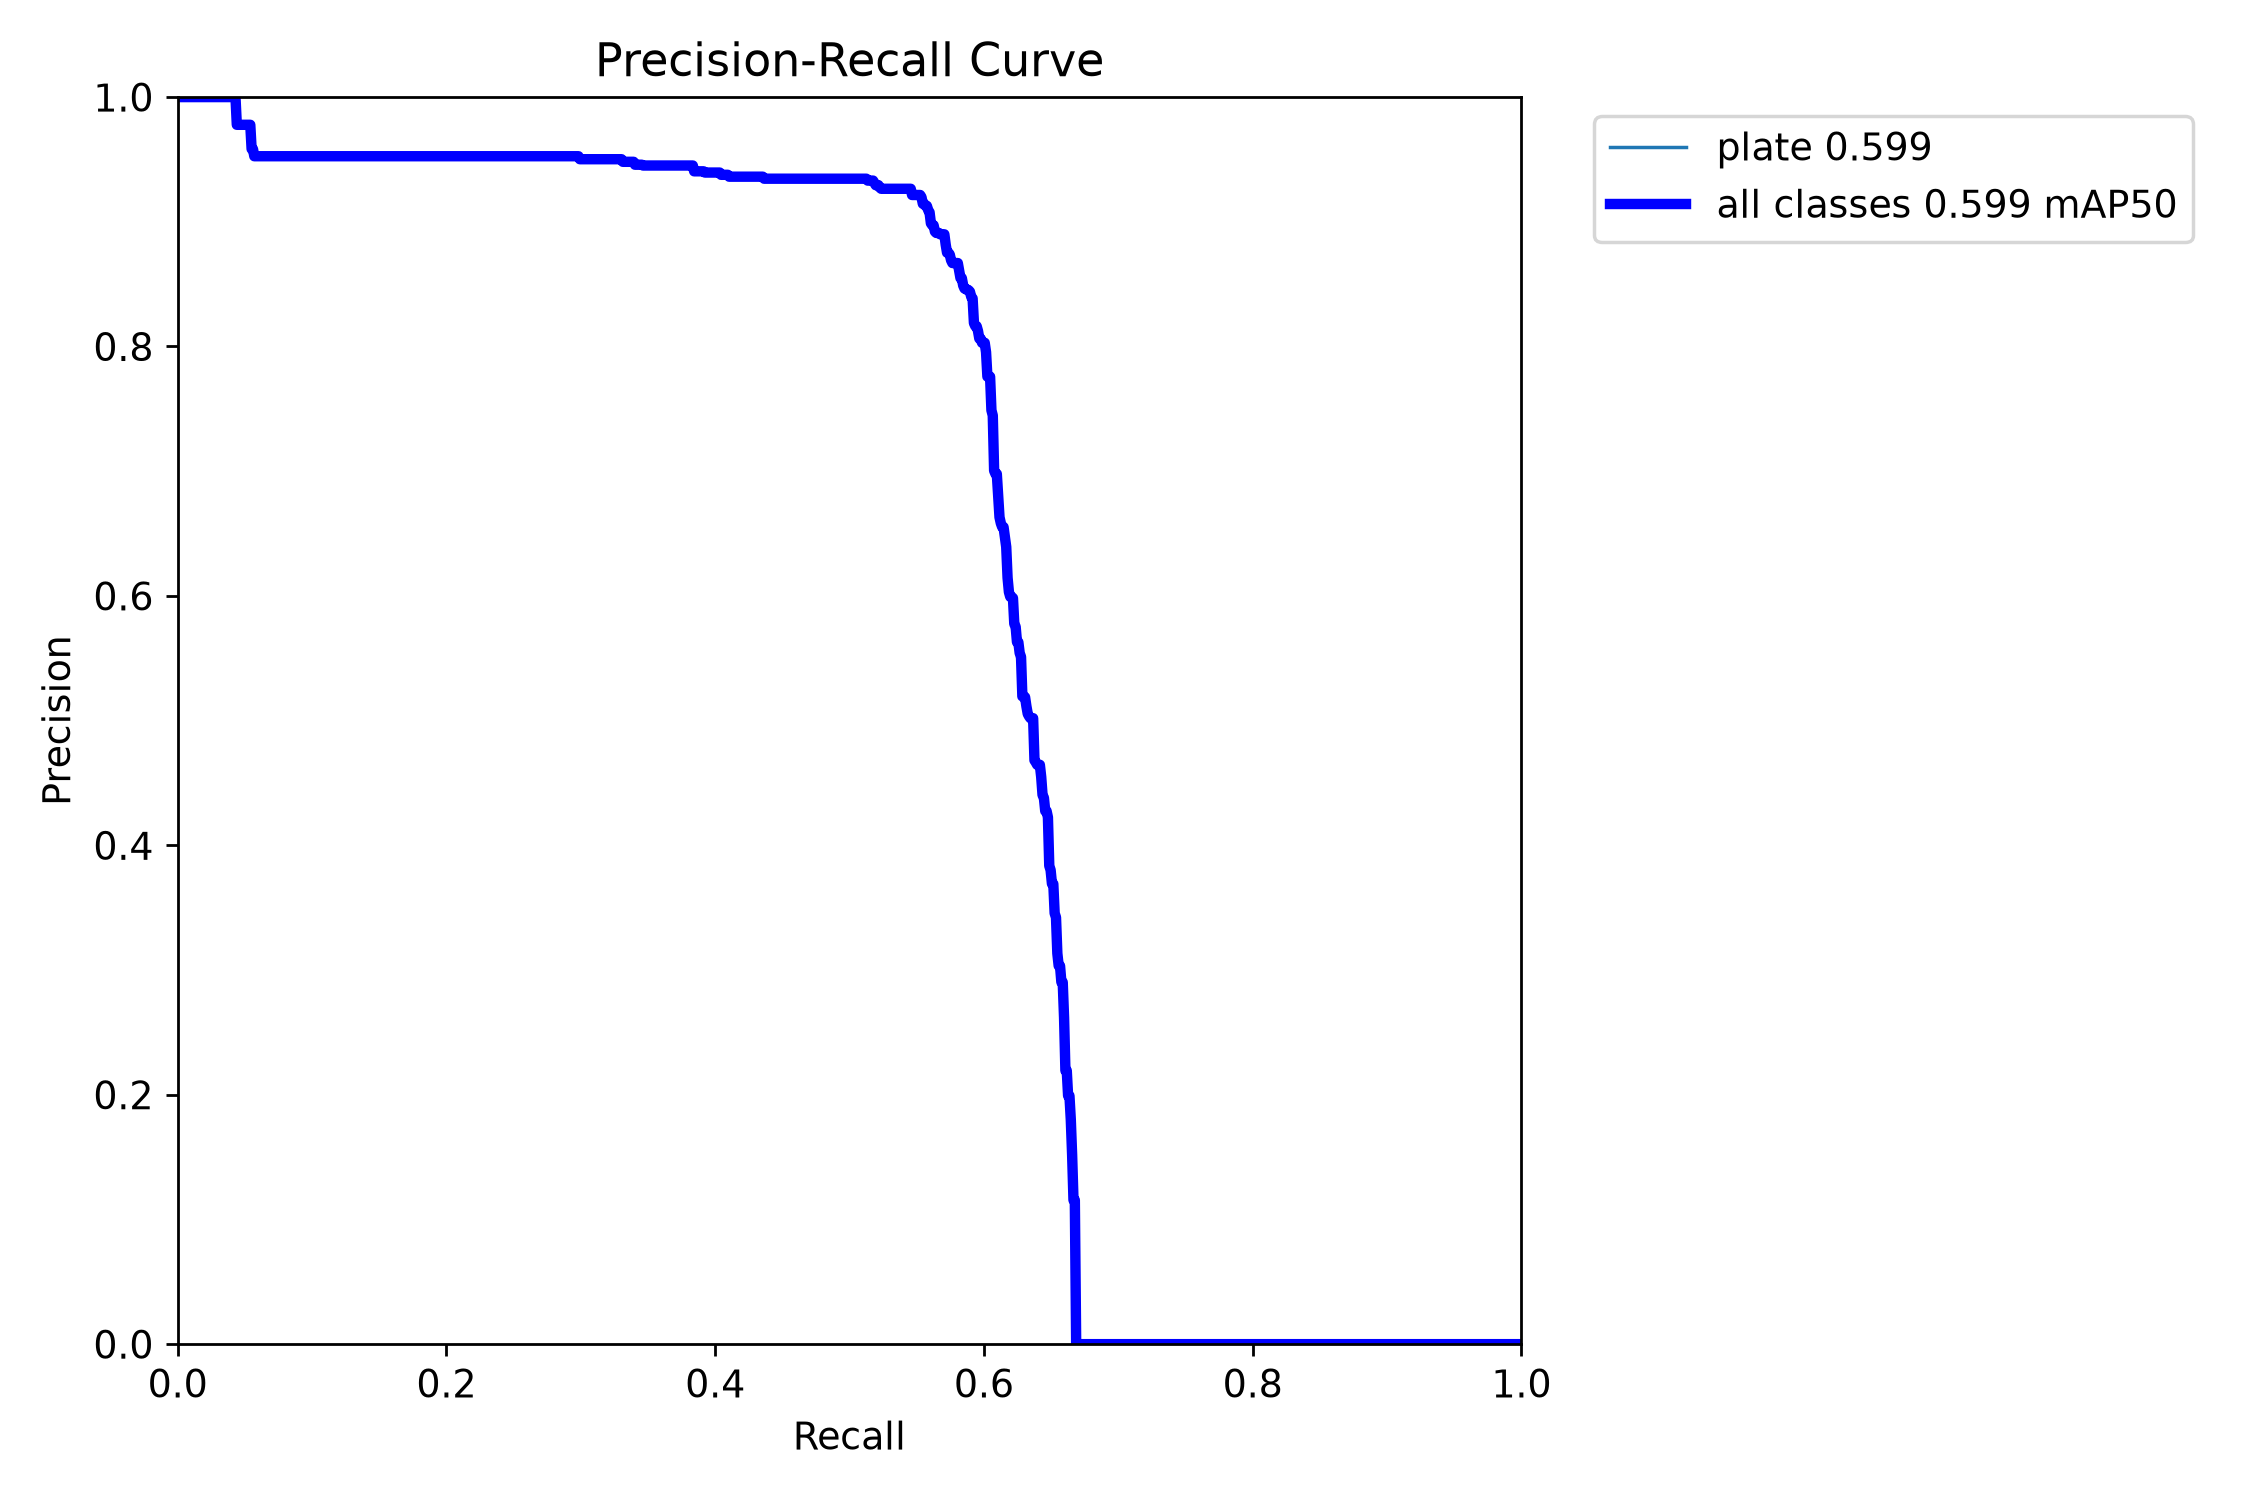

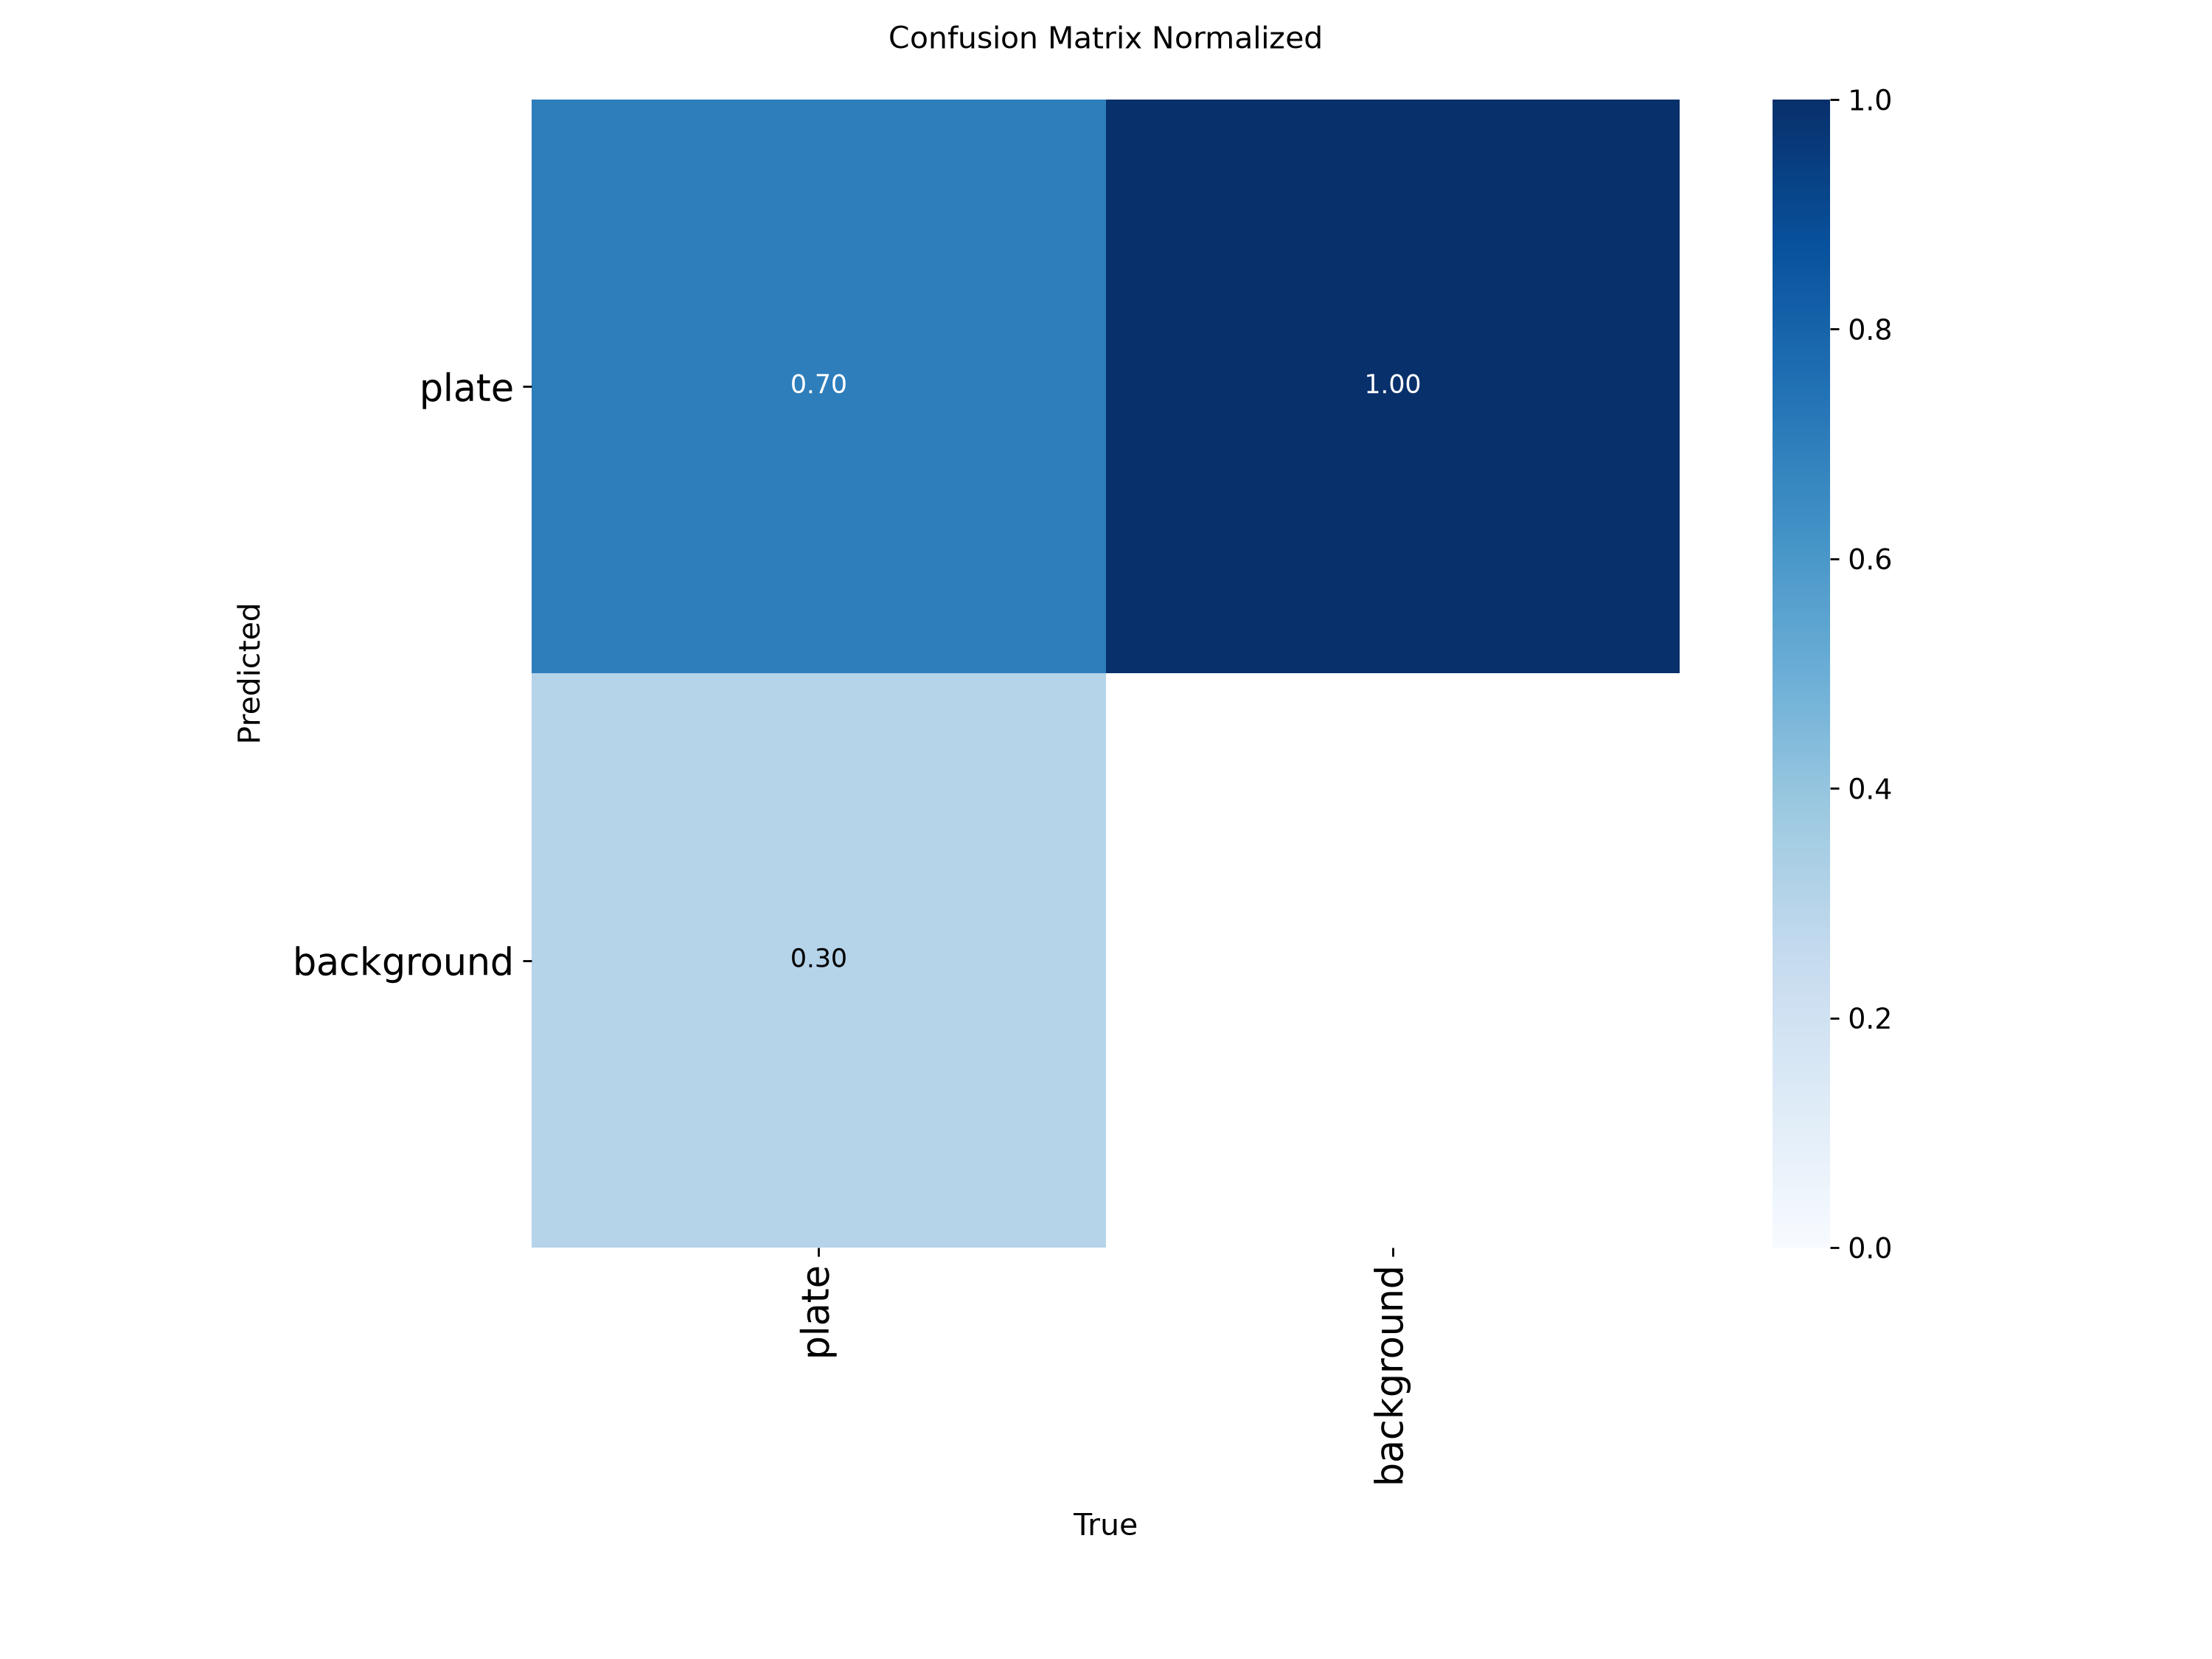

In [8]:
for nombre, carpeta in RUNS.items():
    print('=====', nombre, '=====')
    for archivo in ['results.png', 'BoxPR_curve.png', 'confusion_matrix_normalized.png']:
        if (carpeta / archivo).exists():
            display(MostrarImagen(filename=str(carpeta / archivo), width=800))

## Evaluación en test

In [9]:
filas = []
for nombre, carpeta in RUNS.items():
    modelo = YOLO(carpeta / 'weights' / 'best.pt')
    m = modelo.val(data=str(YAML), split='test', device=0, project='runs_plates', name=nombre + '_test', exist_ok=True)
    filas.append({'modelo': nombre, 'precision': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map})

tabla = pd.DataFrame(filas).round(3).sort_values('mAP50-95', ascending=False).reset_index(drop=True)
tabla.to_csv('comparativa_modelos.csv', index=False)
tabla

Ultralytics 8.4.202  Python-3.11.18 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070 Laptop GPU, 8188MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.3±0.1 ms, read: 370.0±378.1 MB/s, size: 2713.8 KB)
val: Scanning C:\Users\jdmas\OneDrive\Documentos\Ingeniería Informática\4º Año\1º Semestre\Visión por Computador\Práctica\VC-Practicas\P4\yolo_dataset\test\labels... 357 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 357/357 118.4it/s 3.0s.4ss
val: C:\Users\jdmas\OneDrive\Documentos\Ingeniería Informática\4º Año\1º Semestre\Visión por Computador\Práctica\VC-Practicas\P4\yolo_dataset\test\images\20261031_190739.jpg: corrupt JPEG restored and saved
val: C:\Users\jdmas\OneDrive\Documentos\Ingeniería Informática\4º Año\1º Semestre\Visión por Computador\Práctica\VC-Practicas\P4\yolo_dataset\test\images\20261031_190804.jpg: corrupt JPEG restored and saved
val: C:\Users\jdmas\OneDrive\Documentos\Ingeniería Informática

,modelo,precision,recall,mAP50,mAP50-95
0,yolo11n,0.868,0.598,0.628,0.337


## Mejor modelo

Mejor modelo: yolo11n


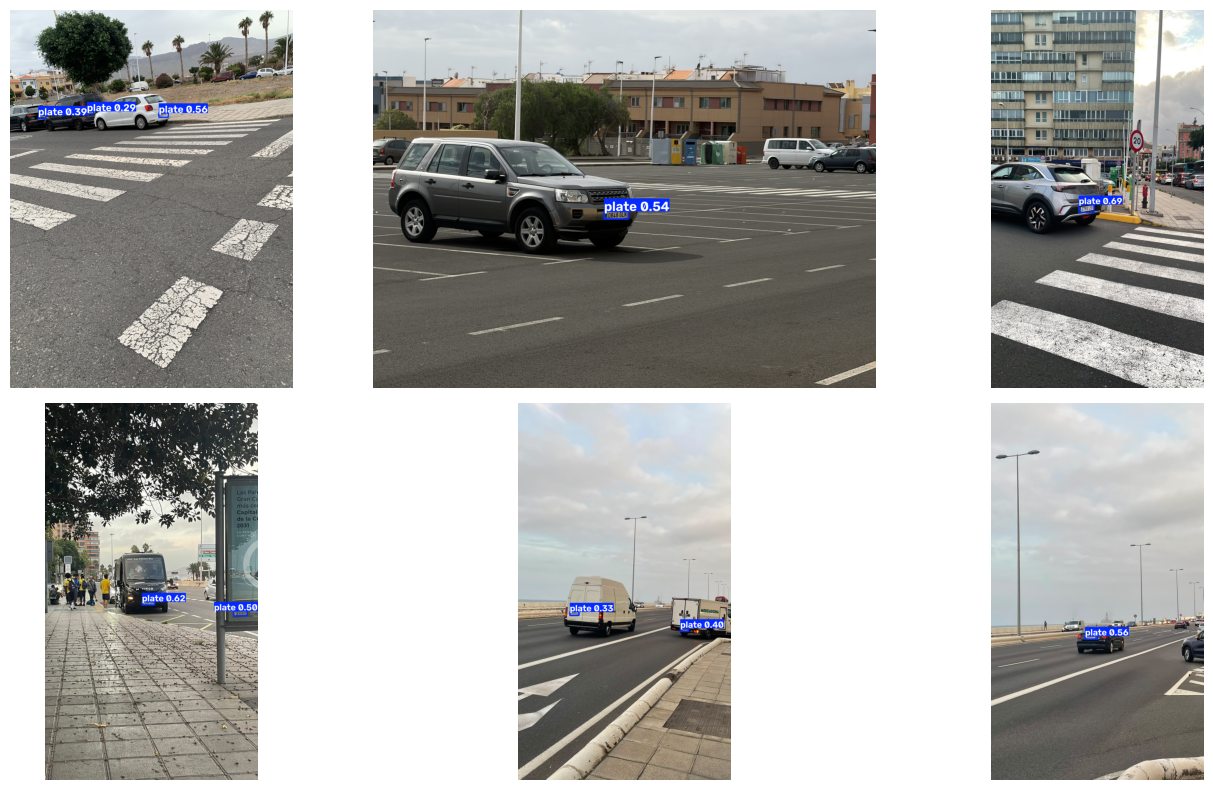

In [10]:
mejor = tabla.loc[0, 'modelo']
shutil.copy2(RUNS[mejor] / 'weights' / 'best.pt', 'matriculas_best.pt')
print('Mejor modelo:', mejor)

modelo = YOLO('matriculas_best.pt')
pruebas = [str(p) for p in sorted((SALIDA / 'test' / 'images').iterdir())[:6]]
resultados = modelo.predict(pruebas, conf=0.25, device=0, verbose=False)

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, r in zip(ejes.ravel(), resultados):
    eje.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    eje.axis('off')
plt.tight_layout()
plt.show()